#Running Libraries

In [ ]:
!pip install dmba
!pip install shap
!pip install lime

In [ ]:
import shap

#pandas and numpy
import pandas as pd
import numpy as np

#Scikit stuff
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, \
                            BaggingClassifier, BaggingRegressor, \
                            GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, \
                            classification_report, precision_score, \
                            accuracy_score, roc_curve, roc_auc_score
# import scikitplot as skplt

#dmba stuff
from dmba import regressionSummary, exhaustive_search
from dmba import adjusted_r2_score, AIC_score, BIC_score
from dmba import classificationSummary, gainsChart, liftChart, plotDecisionTree

# visualization and tuning the aesthetics
import matplotlib.pylab as plt
import seaborn as sns
%matplotlib inline
sns.set_style("whitegrid")
sns.set_context("notebook", font_scale=1, rc={"lines.linewidth": 2,'font.family': [u'times']})
# plt.style.use('seaborn-whitegrid')
plt.rc('text', usetex = False)
plt.rc('font', family = 'serif')
plt.rc('xtick', labelsize = 10)
plt.rc('ytick', labelsize = 10)
plt.rc('font', size = 12)
plt.rc('figure', figsize = (6, 5))


Colab environment detected.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df_world = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/All Dataset for Python (2)/All Dataset for Python/worlddata.csv')
df_world.head()


,CountryName,CountryCode,IndicatorName,IndicatorCode,Year,Value
0,Arab World,ARB,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,1960,1.335609e+02
1,Arab World,ARB,Age dependency ratio (% of working-age populat...,SP.POP.DPND,1960,8.779760e+01
2,Arab World,ARB,"Age dependency ratio, old (% of working-age po...",SP.POP.DPND.OL,1960,6.634579e+00
3,Arab World,ARB,"Age dependency ratio, young (% of working-age ...",SP.POP.DPND.YG,1960,8.102333e+01
4,Arab World,ARB,Arms exports (SIPRI trend indicator values),MS.MIL.XPRT.KD,1960,3.000000e+06


#Data Analysis Pt.1

Within our indicators, we are trying to find which x varriable from our wd_pivot, sub data set, has a stronger correlation to which we our looking for our y.

## Data Analysis Part 1: Variable Selection and Hypotheses

**Research Question:** How do economic development and administrative procedures relate to the time required to register property across countries from 2004 to 2014?

### Y — Time Required to Register Property (Days)
**Dependent Variable (Outcome)**

This variable measures the number of days required to register property. Our objective is to investigate whether economic development and administrative efficiency are associated with differences in property registration times across countries.

### X1 — GDP per Capita (Current US$)

**Hypothesis:** Countries with higher GDP per capita may experience shorter property registration times.

Wealthier economies may possess more developed administrative infrastructure, greater access to technology, and more efficient government institutions. Consequently, higher GDP per capita may be associated with faster property registration processes.

**Expected Correlation:** Negative.

### X2 — Time Required to Start a Business (Days)

**Hypothesis:** Countries with longer business registration times may also experience longer property registration times.
X2 will have the strongest association on our outcome.

Both processes involve government administration and regulatory requirements. Therefore, slower business registration may reflect broader administrative inefficiencies that also affect property registration.

**Expected Correlation:** Positive.

### X3 — Procedures to Register Property (Number)

**Hypothesis:** Countries requiring more procedures to register property may experience longer registration times.

Additional procedures may increase the administrative burden associated with registering property. Conversely, countries requiring fewer procedures may complete the registration process more quickly. However, the efficiency of individual procedures may also influence total registration time.

**Expected Correlation:** Positive.


**Final Goal and Overiview:**: Variable X2 will have the strongest relationships with propertry registrtation time(y) among our three selected indicators!

In [ ]:
# Data Analysis Pt. 1

target_indicators = [
    "GDP per capita (current US$)",
    "Time required to start a business (days)",
    "Procedures to register property (number)",
    "Time required to register property (days)"
]

for indicator in target_indicators:
    years = df_world.loc[
        (df_world["IndicatorName"] == indicator) &
        (df_world["Value"].notna()),
        "Year"
    ]

    print(f"{indicator}: {years.min()} - {years.max()}")

GDP per capita (current US$): 1960 - 2014
Time required to start a business (days): 2003 - 2015
Procedures to register property (number): 2004 - 2015
Time required to register property (days): 2004 - 2015


In [ ]:
target_indicators = [
    "GDP per capita (current US$)",
    "Time required to start a business (days)",
    "Procedures to register property (number)",
    "Time required to register property (days)"
]

filtered_df = df_world[
    (df_world["Year"].between(2004, 2014)) &
    (df_world["IndicatorName"].isin(target_indicators))
]

wd_pivot = filtered_df.pivot_table(
    index=["CountryName", "CountryCode", "Year"],
    columns="IndicatorName",
    values="Value"
).reset_index()

display(wd_pivot.head())

IndicatorName,CountryName,CountryCode,Year,GDP per capita (current US$),Procedures to register property (number),Time required to register property (days),Time required to start a business (days)
0,Afghanistan,AFG,2004,224.914712,11.0,252.0,9.0
1,Afghanistan,AFG,2005,257.175795,11.0,252.0,9.0
2,Afghanistan,AFG,2006,280.245644,11.0,252.0,9.0
3,Afghanistan,AFG,2007,380.400955,9.0,250.0,9.0
4,Afghanistan,AFG,2008,384.131681,9.0,250.0,9.0


In [ ]:
required_variables = [
    "GDP per capita (current US$)",
    "Time required to start a business (days)",
    "Procedures to register property (number)"
]

target_variable = "Time required to register property (days)"

model_df = wd_pivot.dropna(
    subset=required_variables + [target_variable]
)

X = model_df[required_variables]
Y = model_df[target_variable]

print("Complete country-year observations:", len(model_df))
print("Unique countries:", model_df["CountryCode"].nunique())

Complete country-year observations: 2176
Unique countries: 216


The World Data dataset was filtered to include observations from 2004 through 2014 for the four selected indicators. The data was then reshaped from long format into a country-year structure, allowing each indicator to be represented as a separate column.

Observations missing any of the four required variables were excluded to ensure that the correlation and regression analyses used a consistent sample. The resulting dataset contained 2,176 complete country-year observations.

Part 1- Visualizing and Analyzing Factors Associated with Property Registration Time

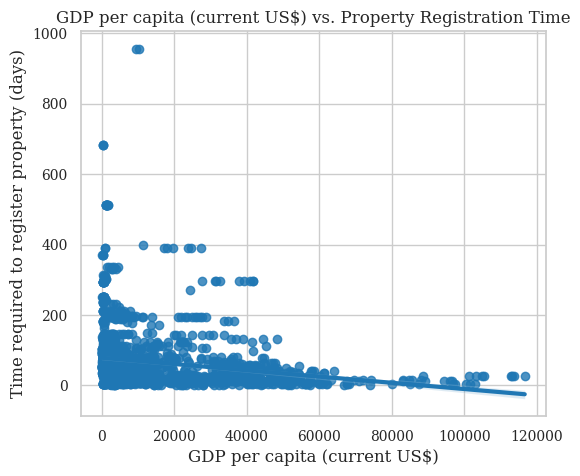

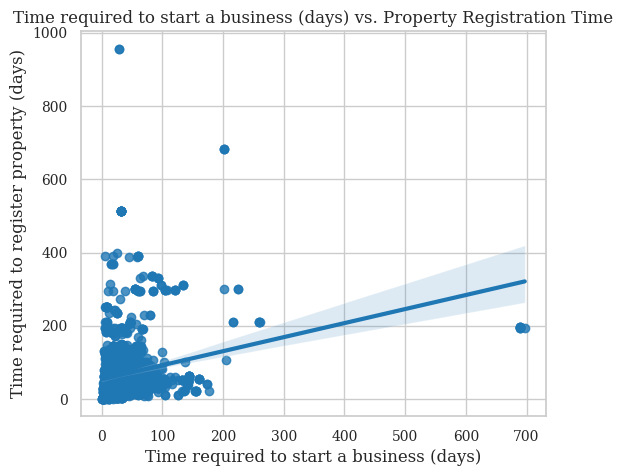

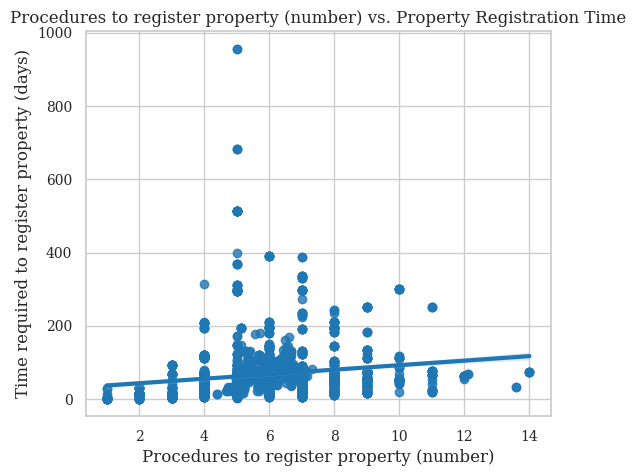

In [ ]:
for variable in required_variables:
    sns.regplot(
        x=variable,
        y=target_variable,
        data=model_df
    )
    plt.title(f"{variable} vs. Property Registration Time")
    plt.show()

**Analysis:**

X1: GDP per capita vs. property registration time
Observed relationship: Negative

The plot shows a downward-sloping regression line, suggesting that countries with higher GDP per capita generally have shorter property registration times.

However, there is considerable variation among countries with lower GDP per capita. Some have registration times below 50 days, while others exceed several hundred days.

This suggests that economic development may be associated with administrative efficiency, but GDP per capita alone does not fully explain differences in registration time.

X2: Business startup time vs. property registration time
Observed relationship: Positive
Supports hypothesis

Shows an upward-sloping regression line. This suggests that countries requiring more time to start a business also tend to require more time to register property.

One possible explanation is that both processes reflect broader administrative efficiency. Countries with slower bureaucratic processes may experience delays across multiple government services.

However, notice that most observations are clustered between approximately 0 and 100 days of business startup time.

There are also extreme observations around 200 and 700 days, which could influence the fitted regression line.

X3: Property registration procedures vs. property registration time
Observed relationship: Positive

The third plot also shows an upward-sloping regression line.

This suggests that countries requiring more procedures to register property generally experience longer registration times.

That makes intuitive sense: additional administrative steps may increase the time needed to complete registration.

However, something interesting appears in your graph.

Countries requiring approximately five or six procedures have registration times ranging from relatively short periods to nearly 1,000 days.

This suggests that the number of procedures alone may not explain registration efficiency. The time required to complete each procedure may also matter.

Additionally, the regression line appears relatively shallow, so we shouldn't assume this relationship is particularly strong without calculating its correlation coefficient.

**Does X2 have the strongest individual correlation with our y variable?**

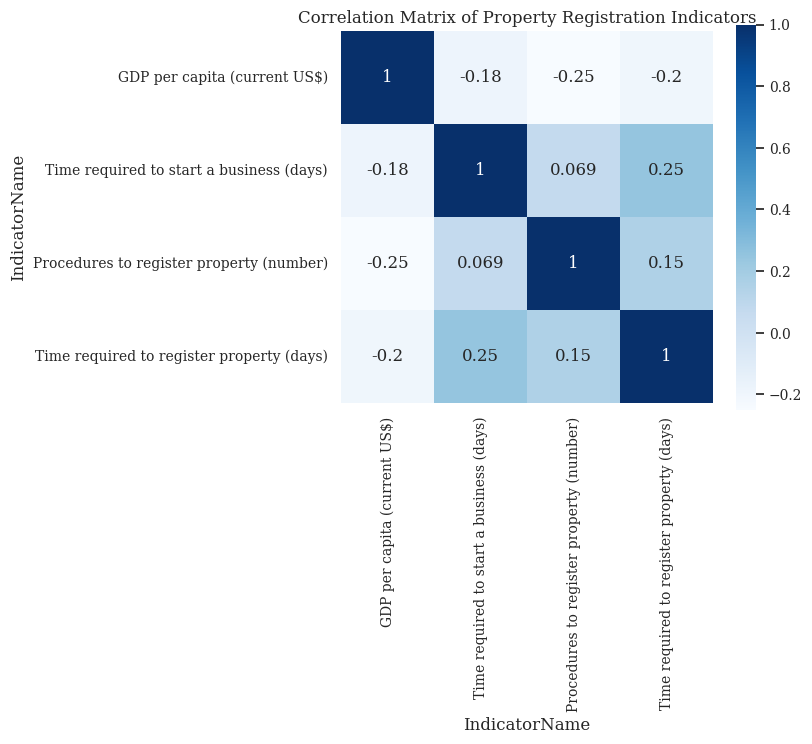

In [ ]:
corrmat = model_df[
    required_variables + [target_variable]
].corr()

sns.heatmap(
    corrmat,
    annot=True,
    square=True,
    cmap="Blues"
)

plt.title("Correlation Matrix of Property Registration Indicators")
plt.show()

**Yes X2 have the strongest correlation with Y variable individually. Does this result hold true when factoring in X1 and X3?** *italicized text*

In [ ]:
import statsmodels.api as sm
y = model_df[target_variable]
X = model_df[required_variables]

X = sm.add_constant(X)

model1 = sm.OLS(y, X)
results1 = model1.fit()

print("R-squared:", results1.rsquared)
print("Observations:", results1.nobs)
print("Correlation with Y:")
print(model_df[required_variables + [target_variable]].corr()[target_variable])

display(results1.summary())

R-squared: 0.09455738025371252
Observations: 2176.0
Correlation with Y:
IndicatorName
GDP per capita (current US$)                -0.197203
Time required to start a business (days)     0.245587
Procedures to register property (number)     0.152634
Time required to register property (days)    1.000000
Name: Time required to register property (days), dtype: float64


<class 'statsmodels.iolib.summary.Summary'>
"""
                                        OLS Regression Results                                       
=====================================================================================================
Dep. Variable:     Time required to register property (days)   R-squared:                       0.095
Model:                                                   OLS   Adj. R-squared:                  0.093
Method:                                        Least Squares   F-statistic:                     75.61
Date:                                       Fri, 20 Nov 2026   Prob (F-statistic):           1.63e-46
Time:                                               17:33:20   Log-Likelihood:                -12491.
No. Observations:                                       2176   AIC:                         2.499e+04
Df Residuals:                                           2172   BIC:                         2.501e+04
Df Model:                                                  3                                         
Covariance Type:                                   nonrobust                                         
============================================================================================================
                                               coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------
const                                       37.7886      5.854      6.455      0.000      26.309      49.268
GDP per capita (current US$)                -0.0006   9.64e-05     -6.148      0.000      -0.001      -0.000
Time required to start a business (days)     0.3340      0.032     10.302      0.000       0.270       0.398
Procedures to register property (number)     4.2388      0.851      4.982      0.000       2.570       5.907
==============================================================================
Omnibus:                     1983.968   Durbin-Watson:                   0.362
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            84921.524
Skew:                           4.241   Prob(JB):                         0.00
Kurtosis:                      32.406   Cond. No.                     7.80e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.8e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Multiple Linear Regression Analysis (OLS)

A multiple linear regression was conducted to examine the relationship between GDP per capita, business startup time, property registration procedures, and property registration time across 2,176 country-year observations from 2004 to 2014.

The model produced an R² of 0.0946, indicating that the three independent variables collectively explain approximately 9.46% of the variation in property registration time. This relatively low R² suggests that additional factors may contribute substantially to differences in registration times across countries.

All three variables had coefficients in their hypothesized directions and were statistically significant under conventional OLS assumptions (p < 0.001). GDP per capita exhibited a negative association, while business startup time and the number of registration procedures exhibited positive associations.

The estimated regression coefficients describe the expected change in property registration time associated with a one-unit increase in each independent variable, holding the other predictors constant.

- **GDP per capita (X1):** A coefficient of approximately −0.0006 indicates that a $10,000 increase in GDP per capita is associated with approximately six fewer property registration days.
- **Business startup time (X2):** A coefficient of 0.3340 indicates that each additional day required to start a business is associated with approximately 0.334 additional property registration days.
- **Property registration procedures (X3):** A coefficient of 4.2388 indicates that each additional procedure is associated with approximately 4.24 additional registration days.

Business startup time exhibited the strongest individual Pearson correlation with property registration time (r = 0.2456). The multiple regression further indicates that its positive association persists after accounting for GDP per capita and registration procedures.

However, the raw regression coefficients cannot be directly compared to identify the strongest conditional predictor because the independent variables are measured in different units. Additionally, subsequent diagnostic testing identified heteroskedasticity, requiring more robust statistical inference before drawing final conclusions about significance.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns

# calculating VIF for each feature
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
vif_data

,feature,VIF
0,const,1.000000
1,GDP per capita (current US$),1.098964
2,Time required to start a business (days),1.035776
3,Procedures to register property (number),1.066750


All three independent variables had VIF values below the threshold of 4, indicating limited problematic multicollinearity. Therefore, substantial linear dependence among the predictors is unlikely to be a major concern when interpreting their regression coefficients.

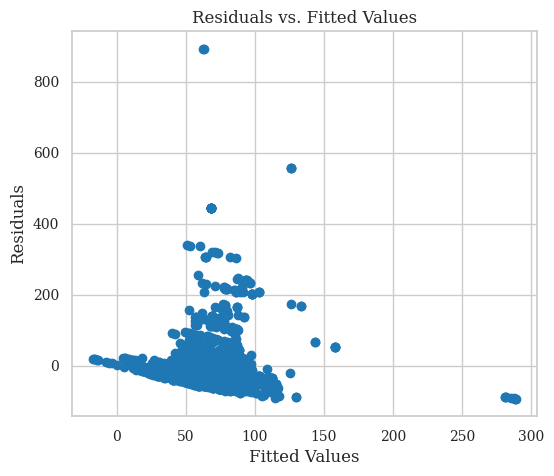

Breusch-Pagan test p-value: 0.00030776035996106483


In [ ]:
# Check for Heteroscedasticity (unequal variance of residuals)
# Calculate residuals from the fitted model
residuals = results1.resid

import statsmodels.stats.api as sms

# Plotting Residuals vs Fitted Values
plt.scatter(results1.fittedvalues, residuals)
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs. Fitted Values')
plt.show()

# Breusch-Pagan test for Heteroscedasticity
_, p_value, _, _ = sms.het_breuschpagan(residuals, model1.exog)
print(f"Breusch-Pagan test p-value: {p_value}")

### Heteroskedasticity Analysis

The Breusch–Pagan test was conducted to assess whether the variance of the regression errors remained constant across observations.

The test returned a p-value of 0.000308, which is below the 0.05 significance threshold. Therefore, the null hypothesis of constant error variance was rejected, providing evidence of heteroskedasticity.

This finding suggests that conventional OLS standard errors and p-values may be unreliable. Although the estimated coefficients are not automatically invalidated, robust standard errors are needed to reassess the statistical significance of the independent variables.

In [ ]:
# Define dependent and independent variables
y = model_df[target_variable]

X = model_df[required_variables]
X = sm.add_constant(X, has_constant="add")

# Fit original OLS regression
model1 = sm.OLS(y, X)
results1 = model1.fit()

# Fit the SAME regression with HC3 robust standard errors
results_robust = model1.fit(cov_type="HC3")

print("Original OLS R²:", results1.rsquared)
print("HC3 Robust R²:", results_robust.rsquared)

display(results_robust.summary())

Original OLS R²: 0.09455738025371252
HC3 Robust R²: 0.09455738025371252


<class 'statsmodels.iolib.summary.Summary'>
"""
                                        OLS Regression Results                                       
=====================================================================================================
Dep. Variable:     Time required to register property (days)   R-squared:                       0.095
Model:                                                   OLS   Adj. R-squared:                  0.093
Method:                                        Least Squares   F-statistic:                     135.7
Date:                                       Fri, 20 Nov 2026   Prob (F-statistic):           1.44e-80
Time:                                               17:33:20   Log-Likelihood:                -12491.
No. Observations:                                       2176   AIC:                         2.499e+04
Df Residuals:                                           2172   BIC:                         2.501e+04
Df Model:                                                  3                                         
Covariance Type:                                         HC3                                         
============================================================================================================
                                               coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------
const                                       37.7886      5.381      7.022      0.000      27.242      48.336
GDP per capita (current US$)                -0.0006   6.89e-05     -8.612      0.000      -0.001      -0.000
Time required to start a business (days)     0.3340      0.050      6.687      0.000       0.236       0.432
Procedures to register property (number)     4.2388      0.728      5.825      0.000       2.812       5.665
==============================================================================
Omnibus:                     1983.968   Durbin-Watson:                   0.362
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            84921.524
Skew:                           4.241   Prob(JB):                         0.00
Kurtosis:                      32.406   Cond. No.                     7.80e+04
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
[2] The condition number is large, 7.8e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
part1_df = model_df.copy()


In [ ]:
part1_df.to_csv(
    "/content/drive/MyDrive/part1_worlddata_cleaned.csv",
    index=False
)

Following the detection of heteroskedasticity, HC3 robust standard errors were applied to improve the reliability of statistical inference. All three independent variables remained statistically significant (p < 0.001), while the regression coefficients and R² (0.0946) remained unchanged.

#Data Analytics Pt.2: Ensemble Regression Models

How can different models predict property registratiopn time using our aforementioned variables?

In [ ]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, \
                            BaggingClassifier, BaggingRegressor, \
                            GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, \
                            classification_report, precision_score, \
                            accuracy_score, roc_curve, roc_auc_score

from dmba import regressionSummary, exhaustive_search
from dmba import adjusted_r2_score, AIC_score, BIC_score
from dmba import classificationSummary, gainsChart, liftChart, plotDecisionTree
part2_df = model_df.copy()

# Define predictors and outcome
X_ml = part2_df[required_variables]
y_ml = part2_df[target_variable]

# Split data into training and testing
train_X, test_X, train_y, test_y = train_test_split(
    X_ml, y_ml,
    test_size=0.2,
    random_state=42
)

# Bagging: Use all 3 predictors at each split
WORLDDATA_DFbag = RandomForestRegressor(
    max_features=3,
    random_state=23
)

# Random Forest: Randomly consider 2 predictors at each split
WORLDDATA_DFrF = RandomForestRegressor(
    max_features=2,
    random_state=23
)

# Gradient Boosting
WORLDDATA_DFboost = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.01,
    random_state=23
)

In [ ]:
# Fit the models on the training data
WORLDDATA_DFbag.fit(train_X, train_y)
WORLDDATA_DFrF.fit(train_X, train_y)
WORLDDATA_DFboost.fit(train_X, train_y)

print("Bagging")
regressionSummary(test_y, WORLDDATA_DFbag.predict(test_X))

print("\nRandom Forest")
regressionSummary(test_y, WORLDDATA_DFrF.predict(test_X))

print("\nGradient Boosting")
regressionSummary(test_y, WORLDDATA_DFboost.predict(test_X))

Bagging

Regression statistics

                      Mean Error (ME) : -1.8549
       Root Mean Squared Error (RMSE) : 57.2035
            Mean Absolute Error (MAE) : 25.1447
          Mean Percentage Error (MPE) : -61.0208
Mean Absolute Percentage Error (MAPE) : 75.1341

Random Forest

Regression statistics

                      Mean Error (ME) : -1.7582
       Root Mean Squared Error (RMSE) : 55.6399
            Mean Absolute Error (MAE) : 25.2134
          Mean Percentage Error (MPE) : -59.5551
Mean Absolute Percentage Error (MAPE) : 74.0539

Gradient Boosting

Regression statistics

                      Mean Error (ME) : -3.3291
       Root Mean Squared Error (RMSE) : 69.2770
            Mean Absolute Error (MAE) : 37.3984
          Mean Percentage Error (MPE) : -98.5562
Mean Absolute Percentage Error (MAPE) : 117.6014


Three ensemble regression models were evaluated using the testing dataset: Bagging, Random Forest, and Gradient Boosting.

Random Forest achieved the lowest RMSE (55.64 days), indicating the best performance when larger prediction errors are penalized more heavily.

Gradient Boosting performed the worst, with an RMSE of 69.28 days.

Overall, Random Forest demonstrated the strongest performance based on RMSE, although Bagging produced comparable results.

#Data Analytics Pt.3: Variable Importance and Partial Dependency Plot

Which variable contributes most to reducing prediction error, through random forrest tree splits?

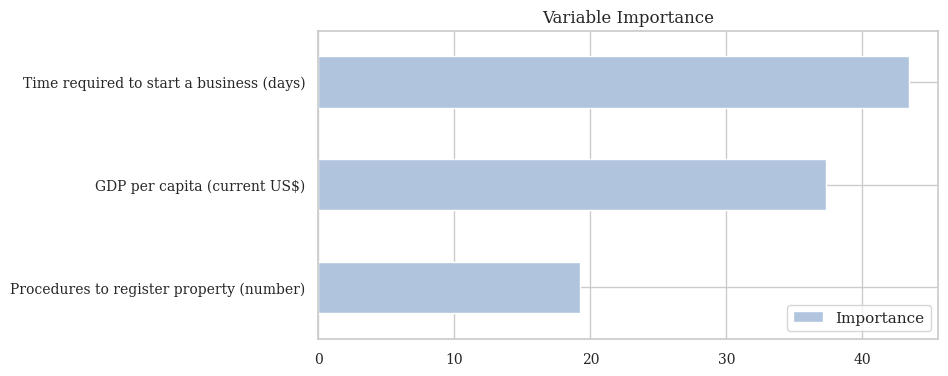

In [ ]:
Importance = pd.DataFrame({'Importance':WORLDDATA_DFrF.feature_importances_*100}, \
                          index=required_variables)
Importance.sort_values('Importance', axis=0, ascending=True).plot(kind='barh', color='lightsteelblue', ) # kind='barh' : Horizontal bar
plt.gcf().set_size_inches(8, 4)
plt.title('Variable Importance')
plt.show()

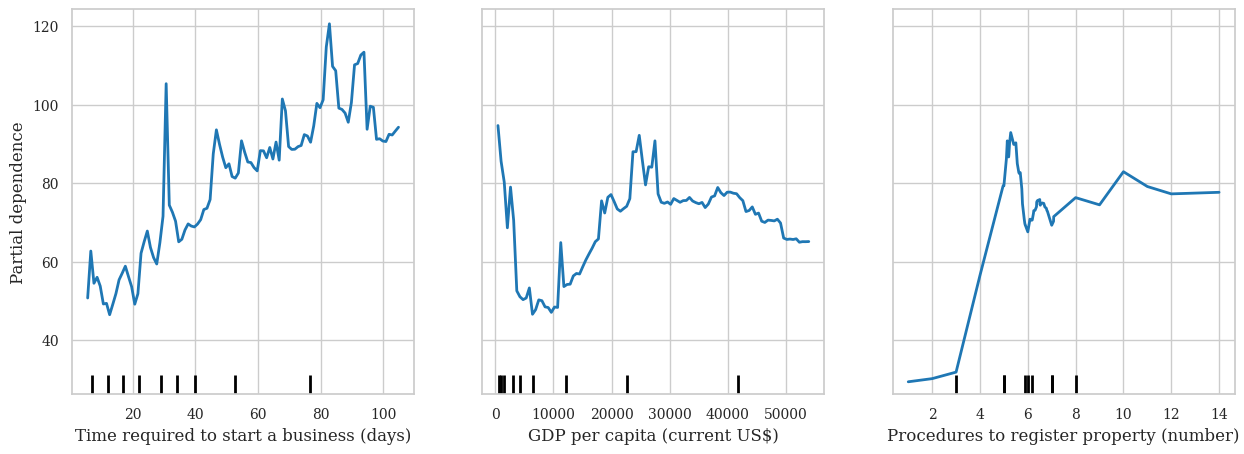

In [ ]:
from sklearn.inspection import PartialDependenceDisplay

# Corrected variable name from 'top 3' to 'top_3'
top_3 = Importance.sort_values('Importance', axis=0, ascending=False).head(3).index.tolist()

PartialDependenceDisplay.from_estimator(WORLDDATA_DFrF, test_X, features=top_3)
plt.gcf().set_size_inches(15, 5)
plt.show()

**Variable Importance and Partial Dependence Analysis**

The Random Forest variable importance analysis identified business startup time (X2) as the most important predictor of property registration time, followed by GDP per capita (X1) and property registration procedures (X3).

The partial dependence plots showed a generally positive relationship between business startup time and predicted property registration time. GDP per capita exhibited a nonlinear relationship, while the number of property registration procedures showed an initial increase in predicted registration time before leveling off.

These findings support the original hypothesis that business startup time is the strongest predictor among the three selected variables in the fitted Random Forest model. However, the results represent predictive associations rather than causal relationships.

#Conclusion

This analysis examined how economic development and administrative efficiency relate to property registration times across countries from 2004 to 2014.

The results indicated that GDP per capita had a negative association with property registration time, while business startup time and the number of property registration procedures exhibited positive associations. All three variables remained statistically significant after applying HC3 robust standard errors to address heteroskedasticity.

Among the ensemble regression models, Random Forest achieved the lowest RMSE (55.64 days), indicating the strongest predictive performance based on this metric. Its variable importance analysis identified business startup time (X2) as the most important predictor, consistent with our original hypothesis. The partial dependence plots also suggested that the relationships between the selected indicators and property registration time were not entirely linear.

Overall, these findings support the hypothesis that business startup time has the strongest association with property registration time among our three selected indicators. This suggests that broader administrative efficiency may play an important role in understanding differences in property registration times across countries.

However, the relatively low explanatory power of the linear regression model (R² = 0.0946) indicates that additional factors may influence registration times. Furthermore, the observed relationships do not establish causation, and future research could investigate additional institutional and regulatory indicators.